# 02 — Modeling & Evaluation

**Goal of this notebook:** given the frozen `wav2vec2` embeddings cached by `01_features.ipynb`, train and honestly evaluate a `fatigued` vs `non_fatigued` classifier — honestly meaning **every number reported here comes from a participant who was never seen during that model's training**, at any level.

**Inputs this notebook needs attached (Kaggle "Add Input"):**
1. The **`Fatigue_data`** dataset (same one attached to notebook 01) — for `labels.csv` and `audio/` (the latter only for a cheap duration-only confound check, not full audio processing).
2. **`01_features`**'s notebook **output** — for `wav2vec2_base.parquet` (the cached embeddings).

**What this notebook does, in order:**
1. Loads embeddings + labels, merges them.
2. Runs **nested, speaker-independent cross-validation** (the core of this notebook) — explained in full below.
3. Reports pooled ROC-AUC and secondary metrics, with a bootstrap confidence interval and a permutation test.
4. Compares against two baselines: a majority-class predictor, and a duration/activity-only "confound" predictor.
5. Repeats the metric suite at the session level (averaging the 3 activities per session).

## Why nested cross-validation, in plain terms

There are two different jobs that both need doing without letting information leak between them:

- **Job A — "how well does this generalize to a brand-new person?"** This needs a test set that shares *zero* participants with training. We use **Leave-One-Speaker-Out (LOSO)**: hold out all of one participant's recordings, train on the other 13, test on the held-out one — and repeat for all 14 participants, so everyone gets a turn as the test case.
- **Job B — "which regularization strength / model type should we use?"** This is a modeling *choice*, and it also must not be made by peeking at the outer test participant (that would be a subtler form of leakage — the classifier itself wouldn't have seen the test speaker's data, but our decision of *how to configure* the classifier would have). So for each of the 14 outer LOSO iterations, we further split the **13 remaining training participants** into 6 groups (`GroupKFold(6)`) and use those splits *purely* to score candidate hyperparameters. The outer test participant is never involved in this inner step.

```
for each of 14 participants P (outer LOSO):
    outer_train = the other 13 participants        outer_test = P
    for each candidate (model type, C):
        score it with GroupKFold(6) *within* outer_train only
    pick the candidate with the best mean inner-CV score
    retrain that candidate ONCE on the full outer_train
    predict ONCE on outer_test  ->  this is P's contribution to the pooled result
```

Two guarantees fall out of this: the outer test participant never influences training *or* hyperparameter choice, and every one of the 14 pooled predictions came from a model that had truly never encountered that person's voice. Both the outer LOSO split and the inner `GroupKFold(6)` split are grouped by `participant_id` — the code below asserts this explicitly rather than trusting it silently, since it's the single most important property of this whole notebook.

**Candidates considered:** L2-regularized logistic regression and linear SVM, each at 5 regularization strengths (`C`) — 10 candidates total, kept deliberately simple and linear (see `PROJECT_PLAN.md` for why: with 14 speakers, more model capacity risks memorizing identities instead of learning fatigue cues).

## 0. Setup

In [1]:
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import soundfile as sf
import matplotlib.pyplot as plt
from tqdm.auto import tqdm

from sklearn.base import clone
from sklearn.decomposition import PCA
from sklearn.exceptions import ConvergenceWarning
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GroupKFold
from sklearn.metrics import roc_auc_score, balanced_accuracy_score, f1_score, confusion_matrix
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import LinearSVC

warnings.filterwarnings("ignore", category=ConvergenceWarning)

RANDOM_SEED = 42

# Same robust resolution strategy as notebook 01 — search recursively rather
# than assume a fixed /kaggle/input/ depth.
LABELS_CSV = next(Path("/kaggle/input").rglob("labels.csv"))
AUDIO_DIR = LABELS_CSV.parent / "audio"
EMBEDDINGS_PARQUET = next(Path("/kaggle/input").rglob("wav2vec2_base.parquet"))

print(f"LABELS_CSV          = {LABELS_CSV}")
print(f"AUDIO_DIR            = {AUDIO_DIR}")
print(f"EMBEDDINGS_PARQUET   = {EMBEDDINGS_PARQUET}")

LABELS_CSV          = /kaggle/input/datasets/tapudatta/fatigue-data/project_data/labels.csv
AUDIO_DIR            = /kaggle/input/datasets/tapudatta/fatigue-data/project_data/audio
EMBEDDINGS_PARQUET   = /kaggle/input/notebooks/tappu1/notebook1-day3/features/wav2vec2_base.parquet


## 1. Load & Merge

Join the cached embeddings (keyed by `filename`) back onto `labels.csv` to recover `participant_id`, `session_number`, `activity_type`, and `label` — the columns the CV protocol groups and evaluates on.

In [2]:
labels = pd.read_csv(LABELS_CSV)
embeddings = pd.read_parquet(EMBEDDINGS_PARQUET)

df = labels.merge(embeddings, on="filename", how="inner")
assert len(df) == len(labels) == 280, f"expected 280 rows after merge, got {len(df)}"

LABEL_MAP = {"non_fatigued": 0, "fatigued": 1}
df["y"] = df["label"].map(LABEL_MAP)
assert df["y"].isna().sum() == 0, "unmapped label value found"

emb_cols = [c for c in df.columns if c.startswith("emb_")]
print(f"Merged shape: {df.shape}  ({len(emb_cols)} embedding dims)")
print(f"Participants: {df['participant_id'].nunique()}")
print(df["label"].value_counts())

Merged shape: (280, 1542)  (1536 embedding dims)
Participants: 14
label
non_fatigued    147
fatigued        133
Name: count, dtype: int64


In [3]:
X = df[emb_cols].to_numpy()
y = df["y"].to_numpy()
groups = df["participant_id"].to_numpy()

print(f"X: {X.shape}, y: {y.shape}, unique participants in groups: {len(np.unique(groups))}")

X: (280, 1536), y: (280,), unique participants in groups: 14


## 2. Candidate Models

10 candidates: 2 model types x 5 regularization strengths. Both wrap `StandardScaler` inside the pipeline so scaling is fit on training folds only, never on validation/test data. `score_fn` returns a continuous score usable for ROC-AUC: `predict_proba` for logistic regression (a true probability), `decision_function` for linear SVM (an unbounded margin — still valid for AUC, which only depends on ranking, not scale).

In [4]:
CANDIDATE_CS = [0.001, 0.01, 0.1, 1.0, 10.0]


def build_pipeline(model_name: str, c: float) -> Pipeline:
    if model_name == "logreg":
        clf = LogisticRegression(C=c, max_iter=5000, class_weight="balanced")
    elif model_name == "linsvc":
        clf = LinearSVC(C=c, max_iter=10000, class_weight="balanced")
    else:
        raise ValueError(model_name)
    return Pipeline([("scaler", StandardScaler()), ("clf", clf)])


def make_candidates():
    return [
        (name, c, build_pipeline(name, c))
        for name in ["logreg", "linsvc"]
        for c in CANDIDATE_CS
    ]


def score_fn(fitted_pipeline: Pipeline, X_in: np.ndarray) -> np.ndarray:
    clf = fitted_pipeline.named_steps["clf"]
    if hasattr(clf, "predict_proba"):
        return fitted_pipeline.predict_proba(X_in)[:, 1]
    return fitted_pipeline.decision_function(X_in)


def best_threshold(scores: np.ndarray, y_true: np.ndarray) -> float:
    """Threshold maximizing balanced accuracy over a set of (score, label) pairs."""
    best_t, best_ba = 0.5, -1.0
    for t in np.unique(scores):
        ba = balanced_accuracy_score(y_true, (scores >= t).astype(int))
        if ba > best_ba:
            best_ba, best_t = ba, t
    return best_t


print(f"{len(make_candidates())} candidates: 2 model types x {len(CANDIDATE_CS)} C values")

10 candidates: 2 model types x 5 C values


## 3. Nested LOSO -> GroupKFold(6) Cross-Validation

This is the function that implements the algorithm sketched above. Two things worth pointing out in the code:

- The `assert` calls are not defensive boilerplate — they are *the* check this whole project hinges on (see `PROJECT_PLAN.md`: "the first thing that will be checked"). If a participant's data ever leaked across an outer or inner split, these would fail loudly rather than silently inflating the score.
- The classification **threshold** for each outer fold is chosen using only that fold's inner-CV validation scores (the winning candidate's pooled inner predictions) — never the outer test participant's data. This keeps threshold selection just as leak-free as hyperparameter selection.

In [5]:
def nested_loso_cv(X, y, groups, n_inner_splits=6, verbose=True):
    participants = np.unique(groups)
    oof_scores = np.zeros(len(y), dtype=float)
    oof_preds = np.zeros(len(y), dtype=int)
    fold_records = []
    n_outer_checked, n_inner_checked = 0, 0

    for test_participant in participants:
        outer_test_mask = groups == test_participant
        outer_train_mask = ~outer_test_mask

        assert not (set(groups[outer_train_mask]) & set(groups[outer_test_mask])), \
            f"outer leakage: {test_participant} present in both outer train and test"
        n_outer_checked += 1

        X_tr, y_tr, g_tr = X[outer_train_mask], y[outer_train_mask], groups[outer_train_mask]
        X_te = X[outer_test_mask]

        candidates = make_candidates()
        cand_aucs = {i: [] for i in range(len(candidates))}
        cand_scores = {i: [] for i in range(len(candidates))}
        cand_labels = {i: [] for i in range(len(candidates))}

        gkf = GroupKFold(n_splits=n_inner_splits)
        for inner_tr_idx, inner_val_idx in gkf.split(X_tr, y_tr, groups=g_tr):
            inner_train_groups = set(g_tr[inner_tr_idx])
            inner_val_groups = set(g_tr[inner_val_idx])
            assert not (inner_train_groups & inner_val_groups), \
                f"inner leakage within outer fold {test_participant}"
            n_inner_checked += 1

            X_itr, y_itr = X_tr[inner_tr_idx], y_tr[inner_tr_idx]
            X_ival, y_ival = X_tr[inner_val_idx], y_tr[inner_val_idx]
            if len(np.unique(y_itr)) < 2 or len(np.unique(y_ival)) < 2:
                continue  # AUC undefined without both classes present

            for i, (_, _, pipe) in enumerate(candidates):
                fitted = clone(pipe).fit(X_itr, y_itr)
                s = score_fn(fitted, X_ival)
                cand_aucs[i].append(roc_auc_score(y_ival, s))
                cand_scores[i].append(s)
                cand_labels[i].append(y_ival)

        mean_aucs = {i: np.mean(v) for i, v in cand_aucs.items() if v}
        best_i = max(mean_aucs, key=mean_aucs.get)
        best_name, best_c, best_template = candidates[best_i]

        pooled_inner_scores = np.concatenate(cand_scores[best_i])
        pooled_inner_labels = np.concatenate(cand_labels[best_i])
        threshold = best_threshold(pooled_inner_scores, pooled_inner_labels)

        final_pipe = clone(best_template).fit(X_tr, y_tr)
        test_scores = score_fn(final_pipe, X_te)
        oof_scores[outer_test_mask] = test_scores
        oof_preds[outer_test_mask] = (test_scores >= threshold).astype(int)

        fold_records.append({
            "test_participant": test_participant,
            "n_test": int(outer_test_mask.sum()),
            "chosen_model": best_name,
            "chosen_C": best_c,
            "inner_cv_auc": mean_aucs[best_i],
            "threshold": threshold,
        })

    if verbose:
        print(f"Verified zero participant overlap: {n_outer_checked} outer folds, "
              f"{n_inner_checked} inner GroupKFold(6) splits.")

    return oof_scores, oof_preds, pd.DataFrame(fold_records)

In [6]:
oof_scores, oof_preds, fold_info = nested_loso_cv(X, y, groups)
df["oof_score"] = oof_scores
df["oof_pred"] = oof_preds
fold_info

Verified zero participant overlap: 14 outer folds, 84 inner GroupKFold(6) splits.


,test_participant,n_test,chosen_model,chosen_C,inner_cv_auc,threshold
0,P-33B7FA2A,6,logreg,0.001,0.541629,0.655075
1,P-4B5527A7,21,logreg,0.001,0.573419,0.621019
2,P-4F8CDB03,20,logreg,0.001,0.566829,0.628880
3,P-57C20427,42,logreg,0.001,0.596703,0.442236
4,P-5AE2B073,6,logreg,0.001,0.533358,0.727475
5,P-66395191,21,logreg,0.001,0.546421,0.516711
6,P-7DB1F098,42,logreg,0.001,0.592476,0.781112
7,P-87C2E2A3,21,logreg,0.001,0.568350,0.607383
8,P-8A4B73A3,11,logreg,0.001,0.576411,0.605410
9,P-B116746A,12,logreg,0.001,0.587539,0.536968


## 4. Pooled Metrics

All 280 out-of-fold predictions (each produced by a model that never saw that participant) are pooled together before computing metrics — more stable than averaging 14 small, uneven-sized per-fold scores, per `PROJECT_PLAN.md`.

In [7]:
pooled_auc = roc_auc_score(y, oof_scores)
balanced_acc = balanced_accuracy_score(y, oof_preds)
f1 = f1_score(y, oof_preds)
tn, fp, fn, tp = confusion_matrix(y, oof_preds).ravel()
sensitivity = tp / (tp + fn)  # recall on the 'fatigued' class
specificity = tn / (tn + fp)  # recall on the 'non_fatigued' class

print(f"Pooled ROC-AUC:      {pooled_auc:.3f}")
print(f"Balanced accuracy:   {balanced_acc:.3f}")
print(f"F1 (fatigued class): {f1:.3f}")
print(f"Sensitivity:         {sensitivity:.3f}")
print(f"Specificity:         {specificity:.3f}")
print(f"Confusion matrix [[TN FP] [FN TP]]:\n[[{tn} {fp}]\n [{fn} {tp}]]")

Pooled ROC-AUC:      0.542
Balanced accuracy:   0.502
F1 (fatigued class): 0.386
Sensitivity:         0.323
Specificity:         0.680
Confusion matrix [[TN FP] [FN TP]]:
[[100 47]
 [90 43]]


## 5. Per-Participant Fold Diagnostic

A per-fold AUC where possible — this is diagnostic, not the headline number (the pooled AUC above is). Expect high variance and some `NaN`s for the 6-recording participants (a fold's own test set may be single-class, in which case AUC is undefined for that fold alone even though its predictions still contribute correctly to the pooled AUC above).

In [8]:
per_fold_auc = []
for _, row in fold_info.iterrows():
    mask = groups == row["test_participant"]
    y_fold, s_fold = y[mask], oof_scores[mask]
    auc = roc_auc_score(y_fold, s_fold) if len(np.unique(y_fold)) > 1 else np.nan
    per_fold_auc.append(auc)

fold_diagnostic = fold_info.copy()
fold_diagnostic["outer_test_auc"] = per_fold_auc
fold_diagnostic

,test_participant,n_test,chosen_model,chosen_C,inner_cv_auc,threshold,outer_test_auc
0,P-33B7FA2A,6,logreg,0.001,0.541629,0.655075,1.000000
1,P-4B5527A7,21,logreg,0.001,0.573419,0.621019,0.648148
2,P-4F8CDB03,20,logreg,0.001,0.566829,0.628880,0.848485
3,P-57C20427,42,logreg,0.001,0.596703,0.442236,0.597222
4,P-5AE2B073,6,logreg,0.001,0.533358,0.727475,0.666667
5,P-66395191,21,logreg,0.001,0.546421,0.516711,0.638889
6,P-7DB1F098,42,logreg,0.001,0.592476,0.781112,0.662132
7,P-87C2E2A3,21,logreg,0.001,0.568350,0.607383,0.750000
8,P-8A4B73A3,11,logreg,0.001,0.576411,0.605410,0.000000
9,P-B116746A,12,logreg,0.001,0.587539,0.536968,0.333333


## 6. Bootstrap Confidence Interval

Resample **participants** with replacement (not individual recordings) B=1000 times, recomputing pooled AUC each time. Resampling participants (rather than rows) respects the grouped structure of the data — resampling rows would treat correlated recordings from the same person as independent evidence, understating the true uncertainty.

In [9]:
def bootstrap_auc_ci(df, n_boot=1000, seed=RANDOM_SEED):
    rng = np.random.default_rng(seed)
    participants = df["participant_id"].unique()
    by_participant = {p: df[df["participant_id"] == p] for p in participants}

    boot_aucs = []
    for _ in range(n_boot):
        sampled = rng.choice(participants, size=len(participants), replace=True)
        rows = pd.concat([by_participant[p] for p in sampled])
        if rows["y"].nunique() < 2:
            continue  # skip the rare resample with only one class present
        boot_aucs.append(roc_auc_score(rows["y"], rows["oof_score"]))

    lo, hi = np.percentile(boot_aucs, [2.5, 97.5])
    return lo, hi, np.array(boot_aucs)


ci_lo, ci_hi, boot_aucs = bootstrap_auc_ci(df)
print(f"Pooled AUC: {pooled_auc:.3f}  (95% bootstrap CI: [{ci_lo:.3f}, {ci_hi:.3f}], "
      f"{len(boot_aucs)} valid resamples)")

Pooled AUC: 0.542  (95% bootstrap CI: [0.466, 0.621], 1000 valid resamples)


## 7. Baselines

Two sanity checks the real model needs to beat — and one confound it should *not* be secretly relying on:

- **Majority-class baseline:** predict whichever label is more common in each outer training set. Any real model should clearly beat this (a fairly low bar given the near-balanced classes, but still the correct floor).
- **Duration/activity-only baseline:** a classifier given *only* `duration_sec` and `activity_type` (one-hot) — no voice content at all. If this scores meaningfully above chance (AUC well above 0.5), it means something about *how recordings are made* (e.g. fatigued sessions running systematically longer) correlates with the label, and the real model could be exploiting that confound rather than actual vocal fatigue cues. It should sit near AUC ~ 0.5; if not, investigate before trusting the embedding-based result.

In [10]:
majority_preds = np.zeros(len(y), dtype=int)
for p in np.unique(groups):
    outer_train_mask = groups != p
    majority_class = int(pd.Series(y[outer_train_mask]).mode()[0])
    majority_preds[groups == p] = majority_class

maj_balanced_acc = balanced_accuracy_score(y, majority_preds)
maj_f1 = f1_score(y, majority_preds)
print(f"Majority-class baseline: balanced accuracy={maj_balanced_acc:.3f}, F1={maj_f1:.3f} "
      f"(AUC is undefined for a constant prediction, not computed)")

Majority-class baseline: balanced accuracy=0.500, F1=0.000 (AUC is undefined for a constant prediction, not computed)


In [11]:
durations = [sf.info(AUDIO_DIR / f).frames / sf.info(AUDIO_DIR / f).samplerate for f in df["filename"]]
df["duration_sec"] = durations

confound_X = pd.get_dummies(df[["duration_sec", "activity_type"]], columns=["activity_type"]).to_numpy()

confound_scores, confound_preds, confound_fold_info = nested_loso_cv(confound_X, y, groups, verbose=False)
confound_auc = roc_auc_score(y, confound_scores)
print(f"Duration/activity-only baseline pooled AUC: {confound_auc:.3f} "
      f"(expect near 0.5 — a value far above that would mean investigate before trusting the real model)")

Duration/activity-only baseline pooled AUC: 0.494 (expect near 0.5 — a value far above that would mean investigate before trusting the real model)


## 8. Permutation Test

**What this tests:** "is the pooled AUC we got explainable by chance alone?" We break the true link between voice and fatigue label by shuffling labels, rerun the evaluation, and see how often a shuffled ('null') run scores as well as the real run did. If real performance is genuine, it should beat the vast majority of shuffled runs.

**How labels are shuffled:** *within each participant*, across that participant's own sessions — e.g. if a participant has 5 sessions labeled `[F, F, N, N, N]`, a shuffle might reassign them as `[N, F, N, F, N]` to that same participant's 5 sessions. This preserves each participant's own class balance (so the null model can't "win" just by learning a participant's baseline fatigue tendency) and keeps all 3 activity recordings of a session glued to the same (now-shuffled) label, matching the real label structure.

**A computational shortcut, stated explicitly:** re-running the *full* nested hyperparameter search for 500+ permutations would multiply the cost of section 3 by ~500x, for no real benefit — the permutation test is asking whether there's *any* signal at all, not re-litigating which regularization strength is best. So each permutation reuses the **same (model type, C) already chosen per outer fold** in the real run (section 3's `fold_info`), and only refits + repredicts with shuffled labels. This is a standard, defensible tradeoff for nested-CV permutation testing at this scale.

In [12]:
def shuffle_labels_within_participant(df, rng):
    y_perm = df["y"].to_numpy().copy()
    for p, group in df.groupby("participant_id"):
        session_labels = group.drop_duplicates("session_number")[["session_number", "y"]]
        shuffled = session_labels["y"].to_numpy().copy()
        rng.shuffle(shuffled)
        mapping = dict(zip(session_labels["session_number"], shuffled))
        y_perm[group.index] = group["session_number"].map(mapping).to_numpy()
    return y_perm


def run_fixed_hparams_loso(X, y, groups, fold_info):
    oof = np.zeros(len(y), dtype=float)
    for _, row in fold_info.iterrows():
        mask_test = groups == row["test_participant"]
        mask_train = ~mask_test
        if len(np.unique(y[mask_train])) < 2:
            continue
        pipe = build_pipeline(row["chosen_model"], row["chosen_C"])
        fitted = clone(pipe).fit(X[mask_train], y[mask_train])
        oof[mask_test] = score_fn(fitted, X[mask_test])
    return oof

In [13]:
N_PERMUTATIONS = 500  # bump to 1000 for the final reported number; 500 is enough while iterating

rng = np.random.default_rng(RANDOM_SEED)
perm_aucs = []
for _ in tqdm(range(N_PERMUTATIONS), desc="Permutation test"):
    y_perm = shuffle_labels_within_participant(df, rng)
    if len(np.unique(y_perm)) < 2:
        continue
    perm_scores = run_fixed_hparams_loso(X, y_perm, groups, fold_info)
    perm_aucs.append(roc_auc_score(y_perm, perm_scores))

perm_aucs = np.array(perm_aucs)
p_value = (1 + np.sum(perm_aucs >= pooled_auc)) / (1 + len(perm_aucs))

print(f"Observed pooled AUC:  {pooled_auc:.3f}")
print(f"Null (permuted) mean: {perm_aucs.mean():.3f} +/- {perm_aucs.std():.3f}")
print(f"Empirical p-value:    {p_value:.4f}  (fraction of {len(perm_aucs)} permutations scoring >= observed)")

Permutation test:   0%|          | 0/500 [00:00<?, ?it/s]

Observed pooled AUC:  0.542
Null (permuted) mean: 0.496 +/- 0.049
Empirical p-value:    0.1896  (fraction of 500 permutations scoring >= observed)


## 9. Session-Level Fusion

Each session recorded 3 activities that share one label. Averaging their 3 out-of-fold scores into one session-level prediction is a cheap ensembling step — literature on this task shows it typically helps, since it cancels out some of the per-clip noise.

In [14]:
def majority_vote(preds):
    return int(pd.Series(preds).mode()[0])


session_fusion = (
    df.groupby(["participant_id", "session_number"])
    .agg(y=("y", "first"), oof_score=("oof_score", "mean"), oof_pred=("oof_pred", majority_vote))
    .reset_index()
)

session_auc = roc_auc_score(session_fusion["y"], session_fusion["oof_score"])
session_balanced_acc = balanced_accuracy_score(session_fusion["y"], session_fusion["oof_pred"])
session_f1 = f1_score(session_fusion["y"], session_fusion["oof_pred"])

print(f"Per-recording (N={len(df)}):  AUC={pooled_auc:.3f}, balanced acc={balanced_acc:.3f}, F1={f1:.3f}")
print(f"Session-fused (N={len(session_fusion)}):  AUC={session_auc:.3f}, "
      f"balanced acc={session_balanced_acc:.3f}, F1={session_f1:.3f}")

Per-recording (N=280):  AUC=0.542, balanced acc=0.502, F1=0.386
Session-fused (N=94):  AUC=0.547, balanced acc=0.481, F1=0.351


## 10. Results Summary

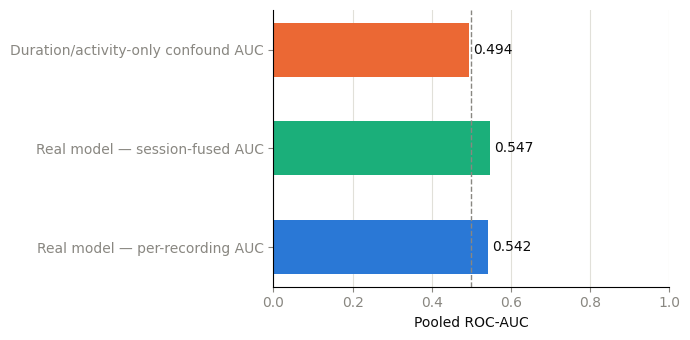


95% bootstrap CI on real model's pooled AUC: [0.466, 0.621]
Permutation test p-value: 0.1896
Majority-class baseline balanced accuracy: 0.500


In [15]:
summary = pd.DataFrame({
    "metric": [
        "Real model — per-recording AUC",
        "Real model — session-fused AUC",
        "Duration/activity-only confound AUC",
    ],
    "value": [pooled_auc, session_auc, confound_auc],
})

COLORS = ["#2a78d6", "#1baf7a", "#eb6834"]  # fixed categorical order: blue, aqua, orange
INK, MUTED, GRID = "#0b0b0b", "#898781", "#e1e0d9"

fig, ax = plt.subplots(figsize=(7, 3.5))
bars = ax.barh(summary["metric"], summary["value"], color=COLORS, height=0.55)
ax.axvline(0.5, color=MUTED, linewidth=1, linestyle="--")
ax.set_xlim(0, 1)
ax.set_xlabel("Pooled ROC-AUC", color=INK)
ax.tick_params(colors=MUTED)
ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="x", color=GRID, linewidth=0.8, zorder=0)
ax.set_axisbelow(True)
for bar, v in zip(bars, summary["value"]):
    ax.text(v + 0.01, bar.get_y() + bar.get_height() / 2, f"{v:.3f}", va="center", color=INK, fontsize=10)
plt.tight_layout()
plt.show()

print(f"\n95% bootstrap CI on real model's pooled AUC: [{ci_lo:.3f}, {ci_hi:.3f}]")
print(f"Permutation test p-value: {p_value:.4f}")
print(f"Majority-class baseline balanced accuracy: {maj_balanced_acc:.3f}")

## How to read these numbers

Per `PROJECT_PLAN.md`'s realistic expectation: with 14 speakers and 280 short clips, this is a hard, small-N problem. A pooled LOSO ROC-AUC meaningfully above 0.5 (e.g. **0.65-0.75**) with a significant permutation p-value is a genuinely good, honest result here — **not** a disappointment next to the ~90% figures in the weaker reference paper (which used a random, non-speaker-independent split — see `PROJECT_PLAN.md` for why that number doesn't mean what it looks like). Conversely:

- If the confound baseline (section 7) scores well above 0.5, the real model's number needs re-examination before trusting it.
- If the real pooled AUC comes back near or above 0.90, that is itself a red flag worth double-checking the no-leakage assertions over, not a result to celebrate uncritically.
- The per-participant diagnostic (section 5) is expected to be noisy, especially for the 6-recording participants — that's an honest limitation of a 14-speaker dataset, not a bug.

## 11. Day 1 — Tier 1 Improvements

The baseline came back near chance (pooled AUC 0.542, 95% CI [0.466, 0.621] crossing 0.5, permutation p=0.19). See `PROJECT_PLAN.md`'s **Improvement plan** section for the full 5–6 day roadmap. Today's changes all reuse the embeddings already cached in `wav2vec2_base.parquet` — no new Kaggle GPU run needed — and all target the same suspect: with only ~252 training recordings per outer fold against 1536 embedding dimensions, the classifier is in a severe `p >> n` regime, and the inner CV's near-universal choice of the strongest regularization (`C=0.001`) is a symptom of that.

**Three independent changes, tested one at a time:**

- **(a) PCA before the classifier** — reduce 1536 dims down to a handful of principal components.
- **(b) Mean-only pooling** — drop the std-pool half of the embedding, keep only the mean (768 dims).
- **(c) Session-level features at train time** — concatenate the 3 activities' embeddings into one richer feature vector per session, instead of only averaging predictions after the fact (as section 9 did).

**Why one at a time, not all three combined:** if we changed all three simultaneously and the result improved (or got worse), there'd be no way to tell which change was responsible. Each variant below starts from the same 1536-dim baseline and changes exactly one thing, so any effect can be attributed to that specific change. Every result — improvement or not — gets logged in the running `results_log` table in section 11d, per the revised Scope decision in `PROJECT_PLAN.md`: report everything tried, not just the winner.

**What's reused vs. new:** `score_fn`, `best_threshold`, `GroupKFold`, and `clone` from sections 2–3 are reused as-is. A new `nested_loso_cv_variant` function below mirrors section 3's `nested_loso_cv` logic (same leak-free asserts, same per-fold inner-CV threshold selection) but accepts an arbitrary list of `(label, pipeline)` candidates instead of the fixed 10 — this is what lets PCA slot in as just another pipeline step. The original `nested_loso_cv` and the baseline results above are untouched, so they stay exactly reproducible.

In [16]:
def build_pipeline_pca(model_name: str, c: float, pca_components: int | None = None) -> Pipeline:
    """Same as section 2's build_pipeline, plus an optional PCA step between
    scaling and the classifier. pca_components=None reproduces the baseline
    pipeline exactly (no PCA)."""
    steps = [("scaler", StandardScaler())]
    if pca_components is not None:
        steps.append(("pca", PCA(n_components=pca_components, random_state=RANDOM_SEED)))
    if model_name == "logreg":
        clf = LogisticRegression(C=c, max_iter=5000, class_weight="balanced")
    elif model_name == "linsvc":
        clf = LinearSVC(C=c, max_iter=10000, class_weight="balanced")
    else:
        raise ValueError(model_name)
    steps.append(("clf", clf))
    return Pipeline(steps)


def make_candidates_linear():
    """The same 10 baseline candidates (section 2), reformatted as (label, pipeline)
    pairs — used for the mean-only and session-level variants, which change the
    input features but not the candidate set."""
    return [
        (f"{name}_C={c}", build_pipeline_pca(name, c, pca_components=None))
        for name in ["logreg", "linsvc"]
        for c in CANDIDATE_CS
    ]


def make_candidates_pca(pca_options=(10, 30, 50)):
    """30 candidates: 2 model types x 5 C values x 3 PCA component counts."""
    return [
        (f"{name}_C={c}_pca={k}", build_pipeline_pca(name, c, pca_components=k))
        for name in ["logreg", "linsvc"]
        for c in CANDIDATE_CS
        for k in pca_options
    ]


def nested_loso_cv_variant(X, y, groups, make_candidates_fn, n_inner_splits=6):
    """Generalized version of section 3's nested_loso_cv: same outer-LOSO ->
    inner-GroupKFold(6) -> per-fold inner-CV threshold algorithm and the same
    leak-free asserts, but candidates are (label, pipeline) pairs from an
    arbitrary generator function instead of the fixed 10 baseline candidates."""
    participants = np.unique(groups)
    oof_scores = np.zeros(len(y), dtype=float)
    oof_preds = np.zeros(len(y), dtype=int)
    fold_records = []
    n_outer_checked, n_inner_checked = 0, 0

    for test_participant in participants:
        outer_test_mask = groups == test_participant
        outer_train_mask = ~outer_test_mask
        assert not (set(groups[outer_train_mask]) & set(groups[outer_test_mask])), \
            f"outer leakage: {test_participant} present in both outer train and test"
        n_outer_checked += 1

        X_tr, y_tr, g_tr = X[outer_train_mask], y[outer_train_mask], groups[outer_train_mask]
        X_te = X[outer_test_mask]

        candidates = make_candidates_fn()
        cand_aucs = {i: [] for i in range(len(candidates))}
        cand_scores = {i: [] for i in range(len(candidates))}
        cand_labels = {i: [] for i in range(len(candidates))}

        gkf = GroupKFold(n_splits=n_inner_splits)
        for inner_tr_idx, inner_val_idx in gkf.split(X_tr, y_tr, groups=g_tr):
            assert not (set(g_tr[inner_tr_idx]) & set(g_tr[inner_val_idx])), \
                f"inner leakage within outer fold {test_participant}"
            n_inner_checked += 1

            X_itr, y_itr = X_tr[inner_tr_idx], y_tr[inner_tr_idx]
            X_ival, y_ival = X_tr[inner_val_idx], y_tr[inner_val_idx]
            if len(np.unique(y_itr)) < 2 or len(np.unique(y_ival)) < 2:
                continue

            for i, (_, pipe) in enumerate(candidates):
                fitted = clone(pipe).fit(X_itr, y_itr)
                s = score_fn(fitted, X_ival)
                cand_aucs[i].append(roc_auc_score(y_ival, s))
                cand_scores[i].append(s)
                cand_labels[i].append(y_ival)

        mean_aucs = {i: np.mean(v) for i, v in cand_aucs.items() if v}
        best_i = max(mean_aucs, key=mean_aucs.get)
        best_label, best_template = candidates[best_i]

        pooled_inner_scores = np.concatenate(cand_scores[best_i])
        pooled_inner_labels = np.concatenate(cand_labels[best_i])
        threshold = best_threshold(pooled_inner_scores, pooled_inner_labels)

        final_pipe = clone(best_template).fit(X_tr, y_tr)
        test_scores = score_fn(final_pipe, X_te)
        oof_scores[outer_test_mask] = test_scores
        oof_preds[outer_test_mask] = (test_scores >= threshold).astype(int)

        fold_records.append({
            "test_participant": test_participant,
            "n_test": int(outer_test_mask.sum()),
            "chosen_candidate": best_label,
            "inner_cv_auc": mean_aucs[best_i],
            "threshold": threshold,
        })

    print(f"Verified zero participant overlap: {n_outer_checked} outer folds, "
          f"{n_inner_checked} inner GroupKFold(6) splits.")
    return oof_scores, oof_preds, pd.DataFrame(fold_records)


def bootstrap_auc_ci_arrays(participant_ids, y_true, scores, n_boot=1000, seed=RANDOM_SEED):
    """Same bootstrap logic as section 6's bootstrap_auc_ci, generalized to take
    plain arrays instead of a fixed-column dataframe, so it works for any variant's
    (possibly smaller, session-level) output."""
    rng = np.random.default_rng(seed)
    participants = np.unique(participant_ids)
    idx_by_participant = {p: np.where(participant_ids == p)[0] for p in participants}

    boot_aucs = []
    for _ in range(n_boot):
        sampled = rng.choice(participants, size=len(participants), replace=True)
        idx = np.concatenate([idx_by_participant[p] for p in sampled])
        y_boot, s_boot = y_true[idx], scores[idx]
        if len(np.unique(y_boot)) < 2:
            continue
        boot_aucs.append(roc_auc_score(y_boot, s_boot))

    lo, hi = np.percentile(boot_aucs, [2.5, 97.5])
    return lo, hi, np.array(boot_aucs)


# Running log of every variant tried, seeded with the baseline already computed above.
results_log = [
    {"variant": "Baseline (mean+std, 1536-dim, no PCA)", "N": len(df),
     "auc": pooled_auc, "ci_lo": ci_lo, "ci_hi": ci_hi},
]
pd.DataFrame(results_log)

,variant,N,auc,ci_lo,ci_hi
0,"Baseline (mean+std, 1536-dim, no PCA)",280,0.542274,0.465988,0.621486


### 11a. PCA before the classifier

**What it does:** inserts a PCA step between scaling and the classifier, fit fresh inside every inner-train and outer-train fold (never on validation/test data — no leakage). PCA finds the directions of maximum variance in the training data and projects onto the top `k` of them, collapsing 1536 dimensions down to `k` (we try 10, 30, 50 as part of the hyperparameter search, alongside the same 5 `C` values and 2 model types — 30 candidates total).

**How it could help:** this directly targets the diagnosed `p >> n` problem. With ~252 training rows and 1536 features, the classifier has almost complete freedom to fit noise; shrinking to a handful of components removes that freedom and forces it to work with a small set of the most informative (by variance) combinations of the original dimensions. If this is why the inner CV kept picking `C=0.001` (maximum shrinkage), a lower-dimensional space should let it use a less extreme, more discriminative setting.

**How it could hurt — the honest caveat:** PCA is *unsupervised*. It picks directions of maximum variance in the data, with no knowledge of the fatigue label. If the biggest source of variance in these embeddings is actually *who is speaking* (speaker identity) rather than *how fatigued they sound*, PCA's top components could be dominated by speaker-identity variance, and the (possibly smaller-variance) fatigue-relevant directions could get truncated away along with the noise. This is genuinely an empirical question, not something to reason out in advance — hence testing it rather than assuming it will help.

In [17]:
oof_pca, preds_pca, fold_info_pca = nested_loso_cv_variant(X, y, groups, make_candidates_pca)

auc_pca = roc_auc_score(y, oof_pca)
ci_lo_pca, ci_hi_pca, _ = bootstrap_auc_ci_arrays(groups, y, oof_pca)

print(f"PCA variant pooled AUC: {auc_pca:.3f}  (95% CI: [{ci_lo_pca:.3f}, {ci_hi_pca:.3f}])")
print(f"Baseline for comparison: {pooled_auc:.3f}  (95% CI: [{ci_lo:.3f}, {ci_hi:.3f}])")
print("\nChosen (model, C, n_components) per outer fold:")
print(fold_info_pca[["test_participant", "chosen_candidate", "inner_cv_auc"]])

results_log.append({
    "variant": "PCA (10/30/50 components, tuned per fold)", "N": len(df),
    "auc": auc_pca, "ci_lo": ci_lo_pca, "ci_hi": ci_hi_pca,
})
pd.DataFrame(results_log)

Verified zero participant overlap: 14 outer folds, 84 inner GroupKFold(6) splits.
PCA variant pooled AUC: 0.559  (95% CI: [0.509, 0.625])
Baseline for comparison: 0.542  (95% CI: [0.466, 0.621])

Chosen (model, C, n_components) per outer fold:
   test_participant       chosen_candidate  inner_cv_auc
0        P-33B7FA2A  logreg_C=0.001_pca=10      0.572738
1        P-4B5527A7  logreg_C=0.001_pca=10      0.638910
2        P-4F8CDB03  logreg_C=0.001_pca=10      0.610250
3        P-57C20427  logreg_C=0.001_pca=30      0.608443
4        P-5AE2B073  logreg_C=0.001_pca=10      0.575819
5        P-66395191    logreg_C=0.1_pca=10      0.630390
6        P-7DB1F098  logreg_C=0.001_pca=10      0.605616
7        P-87C2E2A3  logreg_C=0.001_pca=10      0.602005
8        P-8A4B73A3   logreg_C=0.01_pca=10      0.613389
9        P-B116746A  logreg_C=0.001_pca=50      0.585872
10       P-E0BE51FC  logreg_C=0.001_pca=30      0.610521
11       P-E2F94BC4  logreg_C=0.001_pca=10      0.576363
12       P-FB31

,variant,N,auc,ci_lo,ci_hi
0,"Baseline (mean+std, 1536-dim, no PCA)",280,0.542274,0.465988,0.621486
1,"PCA (10/30/50 components, tuned per fold)",280,0.558539,0.508777,0.624775


### 11b. Mean-only pooling

**What it does:** uses only the first 768 columns of the cached embedding — the mean-pool half — and drops the std-pool half entirely. This needs no re-extraction: `emb_0..emb_767` *are* the mean-pool values already sitting in `wav2vec2_base.parquet` (see `01_features.ipynb`'s pooling step), so this is a one-line slice.

**How it could help:** halves the feature count (1536 -> 768) without touching the classifier or CV protocol at all, so if dimensionality alone is the problem, this should show some of the same benefit as PCA — but via a fixed, interpretable subset instead of a variance-derived projection. It's also a useful diagnostic: if this scores about the same as the full 1536-dim baseline, the std-pool half wasn't contributing much either way.

**How it could hurt — the honest caveat:** the std-pool half was specifically included (see `01_features.ipynb` section 5) to capture *how much a voice's characteristics vary over the clip* — plausibly relevant to fatigue, since a fatigued voice is often described as flatter or more monotone, which shows up as *lower* variance over time. Dropping it outright removes that signal along with whatever noise it also carried. This is the most direct of the three tests: it isolates one specific bet (mean matters more than variability) rather than a general dimensionality reduction.

In [18]:
X_mean_only = X[:, :768]  # emb_0..emb_767 = the mean-pool half; emb_768..emb_1535 = std-pool, dropped

oof_mean, preds_mean, fold_info_mean = nested_loso_cv_variant(X_mean_only, y, groups, make_candidates_linear)

auc_mean = roc_auc_score(y, oof_mean)
ci_lo_mean, ci_hi_mean, _ = bootstrap_auc_ci_arrays(groups, y, oof_mean)

print(f"Mean-only pooled AUC: {auc_mean:.3f}  (95% CI: [{ci_lo_mean:.3f}, {ci_hi_mean:.3f}])")
print(f"Baseline for comparison: {pooled_auc:.3f}  (95% CI: [{ci_lo:.3f}, {ci_hi:.3f}])")

results_log.append({
    "variant": "Mean-only pooling (768-dim, no PCA)", "N": len(df),
    "auc": auc_mean, "ci_lo": ci_lo_mean, "ci_hi": ci_hi_mean,
})
pd.DataFrame(results_log)

Verified zero participant overlap: 14 outer folds, 84 inner GroupKFold(6) splits.
Mean-only pooled AUC: 0.510  (95% CI: [0.447, 0.581])
Baseline for comparison: 0.542  (95% CI: [0.466, 0.621])


,variant,N,auc,ci_lo,ci_hi
0,"Baseline (mean+std, 1536-dim, no PCA)",280,0.542274,0.465988,0.621486
1,"PCA (10/30/50 components, tuned per fold)",280,0.558539,0.508777,0.624775
2,"Mean-only pooling (768-dim, no PCA)",280,0.509539,0.446893,0.580931


### 11c. Session-level features at train time

**What it does:** builds one feature vector per *session* by concatenating that session's `read_aloud` + `read_aloud_nonsense` + `describe_picture` embeddings (1536 dims each -> 4608 dims per session), instead of training on 280 individual recordings and only averaging *predictions* after the fact (section 9's post-hoc fusion). Sessions missing one of the three activities (a few exist per `PROJECT_PLAN.md`) are dropped from this variant, since there's nothing principled to concatenate in their place. Same nested LOSO/GroupKFold(6) protocol, just at the session grain — `participant_id` grouping still applies, so this stays exactly as leak-free as everything else.

**How it could help:** it hands the classifier all three activities' evidence about a session *at once*, rather than asking it to guess from one 10–100 second clip and only combining guesses afterward. If different activities expose fatigue differently (e.g. sustained reading vs. spontaneous description), a model that sees all three together has a chance to combine complementary cues that post-hoc probability-averaging can't recover once each activity's prediction has already collapsed to a single number.

**How it could hurt — the honest caveat:** this makes the `p >> n` problem *worse*, not better — dimensionality *triples* (4608 vs. 1536) while the number of training examples *shrinks* (roughly 80 complete sessions vs. 280 recordings, spread across the same 13 outer-training speakers). This variant is testing a specific hypothesis (combined evidence beats post-hoc averaging) in isolation; if dimensionality turns out to dominate, the fix would be combining this with 11a's PCA later, not concluding session-level fusion doesn't work at all.

In [19]:
ACTIVITY_ORDER = ["read_aloud", "read_aloud_nonsense", "describe_picture"]


def build_session_features(df, emb_cols):
    rows = []
    for (participant, session), group in df.groupby(["participant_id", "session_number"]):
        by_activity = group.set_index("activity_type")
        if not all(a in by_activity.index for a in ACTIVITY_ORDER):
            continue  # incomplete session (missing an activity) — skip, nothing to concatenate
        feats = np.concatenate([by_activity.loc[a, emb_cols].to_numpy(dtype=float) for a in ACTIVITY_ORDER])
        rows.append({
            "participant_id": participant,
            "session_number": session,
            "y": int(by_activity["y"].iloc[0]),
            "features": feats,
        })
    return pd.DataFrame(rows)


session_feat_df = build_session_features(df, emb_cols)
X_session = np.vstack(session_feat_df["features"].to_numpy())
y_session = session_feat_df["y"].to_numpy()
groups_session = session_feat_df["participant_id"].to_numpy()

total_sessions = df.groupby(["participant_id", "session_number"]).ngroups
print(f"Session-level dataset: {X_session.shape}, {len(session_feat_df)}/{total_sessions} complete "
      f"sessions used ({total_sessions - len(session_feat_df)} dropped for a missing activity)")

Session-level dataset: (92, 4608), 92/94 complete sessions used (2 dropped for a missing activity)


In [20]:
oof_sess, preds_sess, fold_info_sess = nested_loso_cv_variant(
    X_session, y_session, groups_session, make_candidates_linear
)

auc_sess = roc_auc_score(y_session, oof_sess)
ci_lo_sess, ci_hi_sess, _ = bootstrap_auc_ci_arrays(groups_session, y_session, oof_sess)

print(f"Session-level (train-time fusion) pooled AUC: {auc_sess:.3f}  "
      f"(95% CI: [{ci_lo_sess:.3f}, {ci_hi_sess:.3f}])")
print(f"Baseline for comparison: {pooled_auc:.3f}  (95% CI: [{ci_lo:.3f}, {ci_hi:.3f}])")
print(f"Section 9's post-hoc session fusion for comparison: {session_auc:.3f}")

results_log.append({
    "variant": f"Session-level train-time fusion (4608-dim, N={len(session_feat_df)})",
    "N": len(session_feat_df), "auc": auc_sess, "ci_lo": ci_lo_sess, "ci_hi": ci_hi_sess,
})
pd.DataFrame(results_log)

Verified zero participant overlap: 14 outer folds, 84 inner GroupKFold(6) splits.
Session-level (train-time fusion) pooled AUC: 0.570  (95% CI: [0.483, 0.695])
Baseline for comparison: 0.542  (95% CI: [0.466, 0.621])
Section 9's post-hoc session fusion for comparison: 0.547


,variant,N,auc,ci_lo,ci_hi
0,"Baseline (mean+std, 1536-dim, no PCA)",280,0.542274,0.465988,0.621486
1,"PCA (10/30/50 components, tuned per fold)",280,0.558539,0.508777,0.624775
2,"Mean-only pooling (768-dim, no PCA)",280,0.509539,0.446893,0.580931
3,"Session-level train-time fusion (4608-dim, N=92)",92,0.570479,0.482951,0.695325


### 11d. Day 1 Results

                                         variant   N      auc    ci_lo    ci_hi
           Baseline (mean+std, 1536-dim, no PCA) 280 0.542274 0.465988 0.621486
       PCA (10/30/50 components, tuned per fold) 280 0.558539 0.508777 0.624775
             Mean-only pooling (768-dim, no PCA) 280 0.509539 0.446893 0.580931
Session-level train-time fusion (4608-dim, N=92)  92 0.570479 0.482951 0.695325


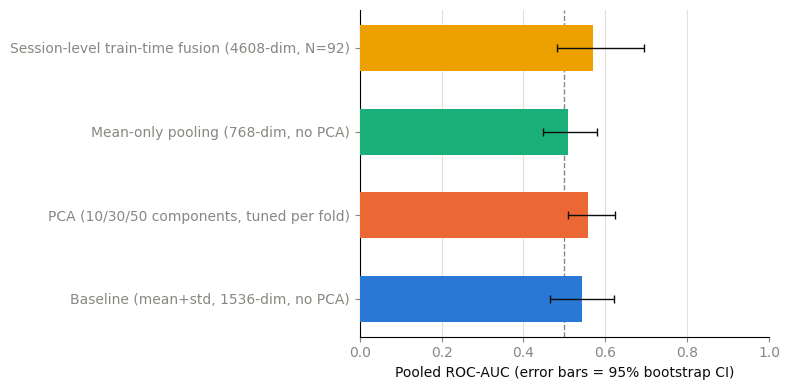

In [21]:
results_df = pd.DataFrame(results_log)
print(results_df.to_string(index=False))

DAY1_COLORS = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100"]  # fixed categorical order: blue/orange/aqua/yellow
INK, MUTED, GRID = "#0b0b0b", "#898781", "#e1e0d9"

fig, ax = plt.subplots(figsize=(8, 4))
y_pos = np.arange(len(results_df))
ax.barh(y_pos, results_df["auc"], color=DAY1_COLORS[: len(results_df)], height=0.55, zorder=3)
ax.errorbar(
    results_df["auc"], y_pos,
    xerr=[results_df["auc"] - results_df["ci_lo"], results_df["ci_hi"] - results_df["auc"]],
    fmt="none", ecolor=INK, elinewidth=1, capsize=3, zorder=4,
)
ax.axvline(0.5, color=MUTED, linewidth=1, linestyle="--", zorder=2)
ax.set_yticks(y_pos)
ax.set_yticklabels(results_df["variant"], color=INK)
ax.set_xlim(0, 1)
ax.set_xlabel("Pooled ROC-AUC (error bars = 95% bootstrap CI)", color=INK)
ax.tick_params(colors=MUTED)
ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="x", color=GRID, linewidth=0.8, zorder=0)
ax.set_axisbelow(True)
plt.tight_layout()
plt.show()

## How to read Day 1's results

Per `PROJECT_PLAN.md`'s Day 1 checkpoint: if any variant's CI lower bound clears 0.5, or the point estimate moves clearly and consistently above baseline, that becomes the new working baseline going into Day 2 (layer selection). If none of the three help, that's still useful information — it means the `p >> n` dimensionality story isn't the main bottleneck, and Day 2–4's embedding-quality experiments (different layers, different SSL models, TRILLsson) become the more promising direction rather than further feature-reduction tricks on this same embedding.

Either way: update `PROJECT_PLAN.md`'s Improvement plan table with today's numbers before moving to Day 2, so the running record stays accurate for whoever (or whichever future session) picks this up next.

## 12. Day 2 — Layer Selection

Day 1 (section 11) came back mixed: PCA cleared the checkpoint only marginally, mean-only pooling made things worse, and session-fusion was promising but unconfirmed. The persistent need for heavy regularization even at 10 PCA components suggested the bottleneck isn't purely `p >> n` — so Day 2 tests a different lever entirely: **which transformer layer the embedding comes from.**

wav2vec2 is trained to predict masked speech content (phoneme-adjacent), which can suppress prosodic/affective information as it flows toward the final layer; the baseline used only the *last* layer (layer 12). This section evaluates **all 13 layers independently** — same 1536-dim mean+std pooling, same candidate set (`make_candidates_linear`, no PCA, isolating the layer variable alone), same nested LOSO/GroupKFold(6) protocol as everywhere else in this notebook.

**Input needed:** attach `01_features.ipynb`'s latest output again (after its Day 2 section ran and the version was saved) so `wav2vec2_base_all_layers.parquet` is available alongside the original embeddings.

**Built-in sanity check:** layer 12 here is the *same* embedding the baseline (section 3) used, just recomputed through a slightly different code path (`output_hidden_states=True` vs. `last_hidden_state`). Its AUC should land close to the baseline's 0.542 — if it doesn't, that's a bug to chase down before trusting any other layer's number, not evidence that layer 12 changed.

In [22]:
LAYER_EMBEDDINGS_PARQUET = next(Path("/kaggle/input").rglob("wav2vec2_base_all_layers.parquet"))
print(f"LAYER_EMBEDDINGS_PARQUET = {LAYER_EMBEDDINGS_PARQUET}")

layer_embeddings = pd.read_parquet(LAYER_EMBEDDINGS_PARQUET)
df_layers = labels.merge(layer_embeddings, on="filename", how="inner")
assert len(df_layers) == 280, f"expected 280 rows after merge, got {len(df_layers)}"

y_layers = df_layers["label"].map(LABEL_MAP).to_numpy()
groups_layers = df_layers["participant_id"].to_numpy()

N_LAYERS = 13
print(f"Loaded {layer_embeddings.shape[1] - 1} layer-embedding columns across {N_LAYERS} layers")

LAYER_EMBEDDINGS_PARQUET = /kaggle/input/notebooks/tappu1/notebook1-day3/features/wav2vec2_base_all_layers.parquet
Loaded 19968 layer-embedding columns across 13 layers


In [23]:
layer_results = []
for L in range(N_LAYERS):
    layer_cols = [c for c in df_layers.columns if c.startswith(f"layer{L}_emb_")]
    X_layer = df_layers[layer_cols].to_numpy()

    oof_L, preds_L, fold_info_L = nested_loso_cv_variant(X_layer, y_layers, groups_layers, make_candidates_linear)
    auc_L = roc_auc_score(y_layers, oof_L)
    ci_lo_L, ci_hi_L, _ = bootstrap_auc_ci_arrays(groups_layers, y_layers, oof_L)

    layer_results.append({"layer": L, "auc": auc_L, "ci_lo": ci_lo_L, "ci_hi": ci_hi_L})
    print(f"Layer {L:2d}: AUC={auc_L:.3f}  CI=[{ci_lo_L:.3f}, {ci_hi_L:.3f}]")

layer_results_df = pd.DataFrame(layer_results)

Verified zero participant overlap: 14 outer folds, 84 inner GroupKFold(6) splits.
Layer  0: AUC=0.534  CI=[0.465, 0.603]
Verified zero participant overlap: 14 outer folds, 84 inner GroupKFold(6) splits.
Layer  1: AUC=0.560  CI=[0.508, 0.607]
Verified zero participant overlap: 14 outer folds, 84 inner GroupKFold(6) splits.
Layer  2: AUC=0.579  CI=[0.524, 0.639]
Verified zero participant overlap: 14 outer folds, 84 inner GroupKFold(6) splits.
Layer  3: AUC=0.574  CI=[0.502, 0.639]
Verified zero participant overlap: 14 outer folds, 84 inner GroupKFold(6) splits.
Layer  4: AUC=0.549  CI=[0.488, 0.599]
Verified zero participant overlap: 14 outer folds, 84 inner GroupKFold(6) splits.
Layer  5: AUC=0.569  CI=[0.497, 0.649]
Verified zero participant overlap: 14 outer folds, 84 inner GroupKFold(6) splits.
Layer  6: AUC=0.538  CI=[0.469, 0.608]
Verified zero participant overlap: 14 outer folds, 84 inner GroupKFold(6) splits.
Layer  7: AUC=0.581  CI=[0.507, 0.634]
Verified zero participant overla

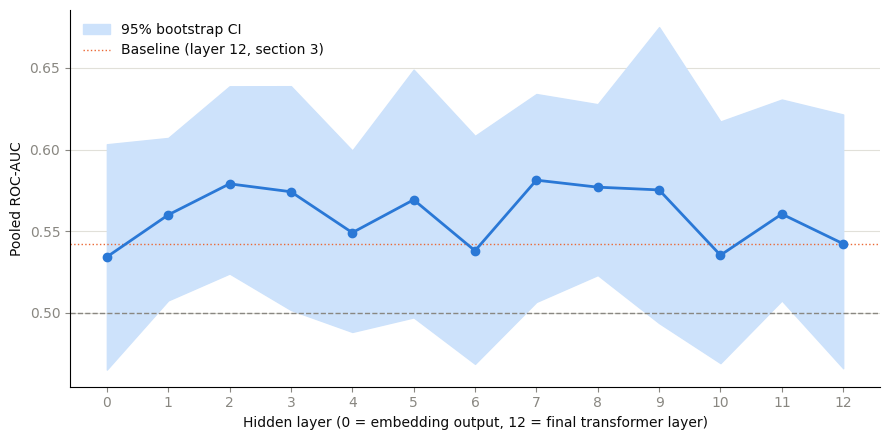

Best layer: 7  AUC=0.581  CI=[0.507, 0.634]

Sanity check — layer 12 here: AUC=0.542 vs. section 3 baseline: 0.542 (should be close; large gap = investigate)


In [24]:
SEQ_LINE = "#2a78d6"   # sequential single hue: blue
SEQ_BAND = "#cde2fb"   # lightest step of the same blue ramp, for the CI band
INK, MUTED, GRID = "#0b0b0b", "#898781", "#e1e0d9"

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.fill_between(layer_results_df["layer"], layer_results_df["ci_lo"], layer_results_df["ci_hi"],
                 color=SEQ_BAND, zorder=1, label="95% bootstrap CI")
ax.plot(layer_results_df["layer"], layer_results_df["auc"], color=SEQ_LINE, marker="o",
        markersize=6, linewidth=2, zorder=3)
ax.axhline(0.5, color=MUTED, linewidth=1, linestyle="--", zorder=2)
ax.axhline(pooled_auc, color="#eb6834", linewidth=1, linestyle=":", zorder=2, label="Baseline (layer 12, section 3)")
ax.set_xticks(range(N_LAYERS))
ax.set_xlabel("Hidden layer (0 = embedding output, 12 = final transformer layer)", color=INK)
ax.set_ylabel("Pooled ROC-AUC", color=INK)
ax.tick_params(colors=MUTED)
ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="y", color=GRID, linewidth=0.8, zorder=0)
ax.set_axisbelow(True)
ax.legend(frameon=False, labelcolor=INK, loc="upper left")
plt.tight_layout()
plt.show()

best_row = layer_results_df.loc[layer_results_df["auc"].idxmax()]
print(f"Best layer: {int(best_row['layer'])}  AUC={best_row['auc']:.3f}  "
      f"CI=[{best_row['ci_lo']:.3f}, {best_row['ci_hi']:.3f}]")
print(f"\nSanity check — layer 12 here: AUC={layer_results_df.loc[12, 'auc']:.3f} "
      f"vs. section 3 baseline: {pooled_auc:.3f} (should be close; large gap = investigate)")

## How to read Day 2's results

Same checkpoint logic as Day 1: if the best layer's CI lower bound clears 0.5 clearly (not by a hair, given the Day 1 PCA lesson about marginal margins), or its point estimate sits clearly and consistently above both the baseline and Day 1's variants, that layer becomes the new working embedding for Day 3 onward — and it's worth re-testing Day 1's PCA / session-fusion combination on top of it, since those were tuned against layer 12 specifically. If every layer scores similarly to the baseline, that argues against "wrong layer" as the explanation and shifts weight toward Day 3 (HuBERT) and Day 4 (TRILLsson) — a different pretraining objective entirely, not just a different readout point from the same model.

Update `PROJECT_PLAN.md`'s Improvement plan with today's numbers (including which layer won and the sanity-check comparison) before moving to Day 3.

## 13. Day 3 — HuBERT-base Layer Selection

Same protocol as Day 2 (section 12), pointed at a different model: `facebook/hubert-base-ls960` instead of `wav2vec2-base`. This tests a different pretraining objective rather than a different readout point of the same model — see `01_features.ipynb` section 8 for why HuBERT is a plausible improvement (its cluster-prediction training tends to preserve more prosodic/suprasegmental information than wav2vec2's contrastive objective). Isolated the same way as every other variant so far: plain 1536-dim mean+std pooling per layer, `make_candidates_linear` (no PCA), no session-fusion — one variable at a time.

**Input needed:** `01_features.ipynb`'s latest output, containing `hubert_base_all_layers.parquet` (section 8 there).

In [25]:
HUBERT_LAYER_EMBEDDINGS_PARQUET = next(Path("/kaggle/input").rglob("hubert_base_all_layers.parquet"))
print(f"HUBERT_LAYER_EMBEDDINGS_PARQUET = {HUBERT_LAYER_EMBEDDINGS_PARQUET}")

hubert_embeddings = pd.read_parquet(HUBERT_LAYER_EMBEDDINGS_PARQUET)
df_hubert = labels.merge(hubert_embeddings, on="filename", how="inner")
assert len(df_hubert) == 280, f"expected 280 rows after merge, got {len(df_hubert)}"

y_hubert = df_hubert["label"].map(LABEL_MAP).to_numpy()
groups_hubert = df_hubert["participant_id"].to_numpy()

hubert_layer_results = []
for L in range(N_LAYERS):
    layer_cols = [c for c in df_hubert.columns if c.startswith(f"layer{L}_emb_")]
    X_layer = df_hubert[layer_cols].to_numpy()

    oof_L, preds_L, fold_info_L = nested_loso_cv_variant(X_layer, y_hubert, groups_hubert, make_candidates_linear)
    auc_L = roc_auc_score(y_hubert, oof_L)
    ci_lo_L, ci_hi_L, _ = bootstrap_auc_ci_arrays(groups_hubert, y_hubert, oof_L)

    hubert_layer_results.append({"layer": L, "auc": auc_L, "ci_lo": ci_lo_L, "ci_hi": ci_hi_L})
    print(f"HuBERT layer {L:2d}: AUC={auc_L:.3f}  CI=[{ci_lo_L:.3f}, {ci_hi_L:.3f}]")

hubert_layer_results_df = pd.DataFrame(hubert_layer_results)

HUBERT_LAYER_EMBEDDINGS_PARQUET = /kaggle/input/notebooks/tappu1/notebook1-day3/features/hubert_base_all_layers.parquet
Verified zero participant overlap: 14 outer folds, 84 inner GroupKFold(6) splits.
HuBERT layer  0: AUC=0.537  CI=[0.451, 0.602]
Verified zero participant overlap: 14 outer folds, 84 inner GroupKFold(6) splits.
HuBERT layer  1: AUC=0.572  CI=[0.506, 0.626]
Verified zero participant overlap: 14 outer folds, 84 inner GroupKFold(6) splits.
HuBERT layer  2: AUC=0.517  CI=[0.471, 0.559]
Verified zero participant overlap: 14 outer folds, 84 inner GroupKFold(6) splits.
HuBERT layer  3: AUC=0.571  CI=[0.512, 0.626]
Verified zero participant overlap: 14 outer folds, 84 inner GroupKFold(6) splits.
HuBERT layer  4: AUC=0.585  CI=[0.520, 0.656]
Verified zero participant overlap: 14 outer folds, 84 inner GroupKFold(6) splits.
HuBERT layer  5: AUC=0.537  CI=[0.469, 0.602]
Verified zero participant overlap: 14 outer folds, 84 inner GroupKFold(6) splits.
HuBERT layer  6: AUC=0.558  CI

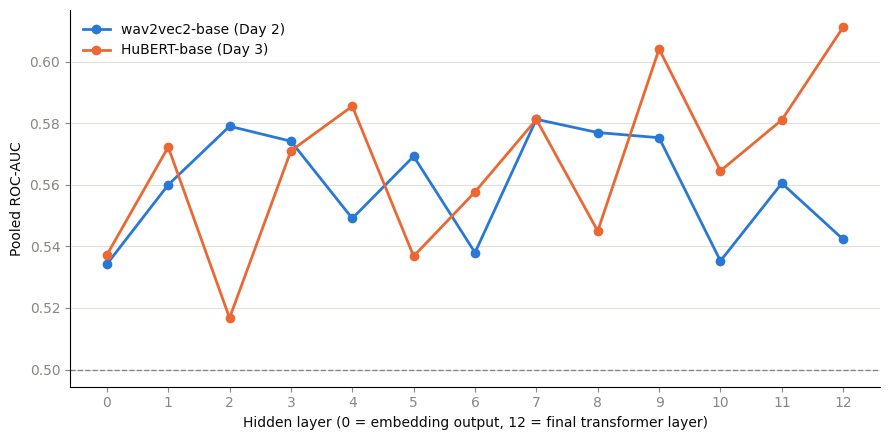

Best wav2vec2 layer: 7  AUC=0.581  CI=[0.507, 0.634]
Best HuBERT layer:   12  AUC=0.611  CI=[0.551, 0.683]


In [26]:
# Fixed categorical order: slot 1 blue = wav2vec2 (already used this color throughout the notebook),
# slot 2 orange = HuBERT.
WAV2VEC2_COLOR = "#2a78d6"
HUBERT_COLOR = "#eb6834"
INK, MUTED, GRID = "#0b0b0b", "#898781", "#e1e0d9"

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.plot(layer_results_df["layer"], layer_results_df["auc"], color=WAV2VEC2_COLOR, marker="o",
        markersize=6, linewidth=2, label="wav2vec2-base (Day 2)")
ax.plot(hubert_layer_results_df["layer"], hubert_layer_results_df["auc"], color=HUBERT_COLOR, marker="o",
        markersize=6, linewidth=2, label="HuBERT-base (Day 3)")
ax.axhline(0.5, color=MUTED, linewidth=1, linestyle="--")
ax.set_xticks(range(N_LAYERS))
ax.set_xlabel("Hidden layer (0 = embedding output, 12 = final transformer layer)", color=INK)
ax.set_ylabel("Pooled ROC-AUC", color=INK)
ax.tick_params(colors=MUTED)
ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="y", color=GRID, linewidth=0.8, zorder=0)
ax.set_axisbelow(True)
ax.legend(frameon=False, labelcolor=INK, loc="upper left")
plt.tight_layout()
plt.show()

best_wav2vec2 = layer_results_df.loc[layer_results_df["auc"].idxmax()]
best_hubert = hubert_layer_results_df.loc[hubert_layer_results_df["auc"].idxmax()]
print(f"Best wav2vec2 layer: {int(best_wav2vec2['layer'])}  AUC={best_wav2vec2['auc']:.3f}  "
      f"CI=[{best_wav2vec2['ci_lo']:.3f}, {best_wav2vec2['ci_hi']:.3f}]")
print(f"Best HuBERT layer:   {int(best_hubert['layer'])}  AUC={best_hubert['auc']:.3f}  "
      f"CI=[{best_hubert['ci_lo']:.3f}, {best_hubert['ci_hi']:.3f}]")

## How to read Day 3's results

Same checkpoint discipline as Days 1–2: a clear, non-marginal win (CI lower bound comfortably above 0.5, or a point estimate consistently ahead of every wav2vec2 layer and every Day 1 variant) makes HuBERT the new working embedding for Day 4 onward. A result similar to wav2vec2's best layer suggests the pretraining objective isn't the deciding factor either, and shifts remaining weight onto Day 4's TRILLsson (a model purpose-built for paralinguistic tasks, not adapted from an ASR-oriented one) as the last embedding-quality lever before moving to data augmentation (Day 5).

Update `PROJECT_PLAN.md`'s Improvement plan with Day 3's numbers (best HuBERT layer, and the wav2vec2-vs-HuBERT comparison) before moving to Day 4.